import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

np.random.seed(1)

In [33]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3


In [34]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [35]:
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. linear combination
z = S @ theta + bias
print(z)                       # [6.3 1.8 4.7 2.2] -> first value is 6.3

# 2. sigmoid + prediction
probabilities = 1 / (1 + np.exp(-z))
print(probabilities)

predicted_spam = probabilities >= 0.5
print(predicted_spam)          # [ True True True True] -> all 4 are spam

[6.3 1.8 4.7 2.2]
[0.99816706 0.85814894 0.9909867  0.90024951]
[ True  True  True  True]


In [36]:
# Auto-graded cell (S)
# Skip it

In [37]:
# Auto-graded cell (theta)
# Skip it

In [38]:
# Auto-graded cell (bias)
# Skip it

In [39]:
# Auto-graded cell (z)
# Skip it

In [40]:
# Auto-graded cell (probabilities)
# Skip it

In [41]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [42]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [43]:
# Auto graded cell (log)
# skip it

In [44]:
idx = np.random.choice(n, 12, replace=False)
log.loc[idx, "failed_attempts"] = np.random.randint(5, 11, 12)

In [45]:
# Autograded cell (Failed attempts)
# Skip it

In [46]:
rows = np.random.choice(n, 10, replace=False)
cols = np.random.choice(log.columns, 10)
for r, c in zip(rows, cols):
    log.loc[r, c] = np.nan
print(log.isna().sum())

user               1
hour               4
failed_attempts    2
country            0
duration_min       3
dtype: int64


In [47]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [48]:
ru_log_at_least_five_attempts = ((log["country"] == "RU") & (log["failed_attempts"] >= 5)).sum()
print(ru_log_at_least_five_attempts)

0


In [49]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [50]:
user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False).index[0]
print(user_max_failed_attempts)    # yacine

yacine


In [51]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [52]:
log["long_session"] = (log["duration_min"] > 30).astype(int)

In [53]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

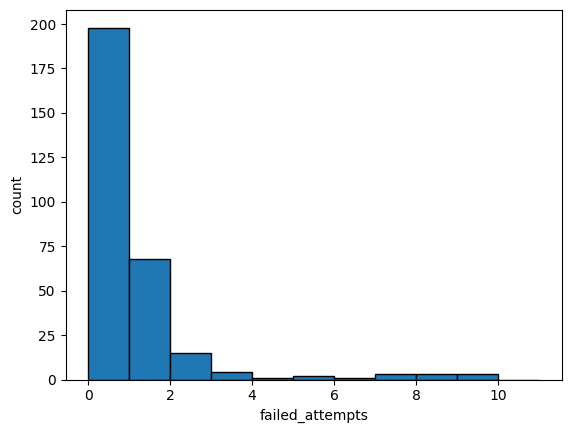

In [54]:
plt.hist(log["failed_attempts"].dropna(), bins=range(0, 12), edgecolor="black")
plt.xlabel("failed_attempts")
plt.ylabel("count")
plt.show()

In [55]:
# Auto-graded cell - Skip it...

2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [56]:
answer_q2 = "B"

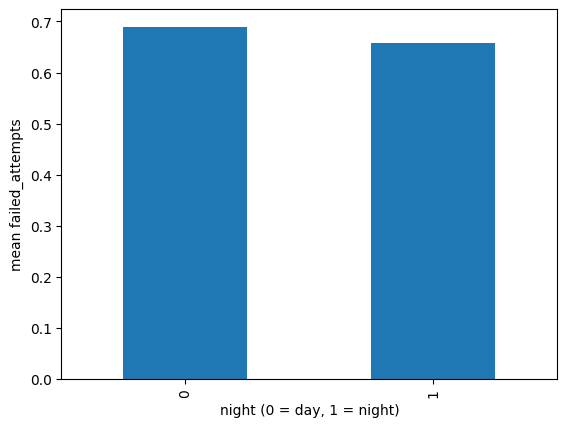

In [57]:
log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

log.groupby("night")["failed_attempts"].mean().plot(kind="bar")
plt.xlabel("night (0 = day, 1 = night)")
plt.ylabel("mean failed_attempts")
plt.show()

In [58]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

 X[:, 2] returns the whole third column of X (all 300 rows, column index 2), as a 1-D array of shape (300,).

In [59]:
# Write your code here


Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [60]:
# Write your code here
df.isna().sum()      # or df.isnull().sum()

NameError: name 'df' is not defined

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
# A boxplot of failed_attempts for each country (RU vs DZ):
sns.boxplot(x="country", y="failed_attempts", data=log)
plt.show()

In [ ]:
# Write your code here

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
# Because features have different ranges/units, scaling puts them on the same scale so that no feature dominates the model.

Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
# Write your code here
log_clean = log.dropna()            # remove the rows with missing values
log_clean.to_csv("logins_clean.csv", index=False)
print(log_clean.shape)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
# Write your code here
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]
X = df[cols].to_numpy()

# standardization: (x - mean) / std for each column
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print(X_scaled.shape)

In [ ]:
import numpy as np
import pandas as pd
